# Module 1 · Notebook 02 — scVI integration + annotation check

Smillie et al. 2019 ulcerative colitis atlas (365k cells). Notebook 01 ran an unintegrated pass; here we integrate across samples with **scVI**, re-cluster on the latent space, and measure how well the new clusters recover the author's 51 published labels.

**Outputs:** UMAP figures in `../figures/`, `adata_scvi.h5ad` next to the source data.

In [4]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import scvi

sc.settings.verbosity = 2
sc.settings.figdir = "../figures"
os.makedirs("../figures", exist_ok=True)

candidates = [
    os.path.expanduser("~/Documents/immune-endotypes/data/smillie_uc/adata_qc.h5ad"),
    "adata_qc.h5ad",
    "../adata_qc.h5ad",
]
path = next((p for p in candidates if os.path.exists(p)), None)
assert path, "adata_qc.h5ad not found — tell Muse where notebook 01 saved it"
adata = sc.read_h5ad(path)
print(path)
print(adata)

/Users/juehuayu/Documents/immune-endotypes/data/smillie_uc/adata_qc.h5ad
AnnData object with n_obs × n_vars = 351952 × 18172
    obs: 'Origin', 'Subject', 'Sample', 'Location', 'Replicate', 'Health', 'Cluster', 'nGene', 'nUMI', 'Major_l1', 'Major_l2', 'Major_l3', 'Major_l4', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'leiden_0.5'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'leiden_0.5', 'leiden_0.5_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'


In [6]:
# scVI works on raw counts; select HVGs per sample batch
adata.X = adata.layers["counts"].copy()
sc.pp.highly_variable_genes(
    adata, layer="counts", n_top_genes=3000,
    batch_key="Sample", flavor="seurat_v3", subset=True,
)
print(adata)

extracting highly variable genes
AnnData object with n_obs × n_vars = 351952 × 3000
    obs: 'Origin', 'Subject', 'Sample', 'Location', 'Replicate', 'Health', 'Cluster', 'nGene', 'nUMI', 'Major_l1', 'Major_l2', 'Major_l3', 'Major_l4', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'leiden_0.5'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_rank', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'hvg', 'leiden_0.5', 'leiden_0.5_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'


In [9]:
adata.obs = adata.obs.rename(columns={"Health": "condition", "Location": "site", "Cluster": "author_label"})
print([c for c in ["condition", "site", "author_label"] if c in adata.obs.columns])


['condition', 'site', 'author_label']


Training runs on CPU — at ~350k cells scVI's default schedule is ~23 epochs; expect tens of minutes. Let it finish.

In [7]:
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="Sample")
model = scvi.model.SCVI(adata, n_latent=30)
model.train()

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/juehuayu/miniconda3/envs/endotypes/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/juehuayu/miniconda3/envs/endotypes/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


Epoch 23/23: 100%|██████████████████████████████| 23/23 [39:36<00:00, 91.35s/it, v_num=1, train_loss=657]

`Trainer.fit` stopped: `max_epochs=23` reached.


Epoch 23/23: 100%|█████████████████████████████| 23/23 [39:36<00:00, 103.34s/it, v_num=1, train_loss=657]


In [8]:
adata.obsm["X_scVI"] = model.get_latent_representation()
sc.pp.neighbors(adata, use_rep="X_scVI", n_neighbors=15)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.5, key_added="leiden_scvi")
sc.pl.umap(
    adata,
    color=["condition", "Major_l2", "author_label", "leiden_scvi"],
    ncols=2, save="_scvi_overview.png",
)
print(adata.obs["leiden_scvi"].nunique(), "scVI clusters")

computing neighbors
    finished (0:00:46)
computing UMAP
    finished (0:05:22)
running Leiden clustering


/var/folders/l9/sgc71zs16rzd_nfvlhsbrkjc0000gn/T/ipykernel_95079/534425053.py:4: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution=0.5, key_added="leiden_scvi")


    finished (0:08:05)


KeyError: 'condition'

<Figure size 1455.6x960 with 0 Axes>

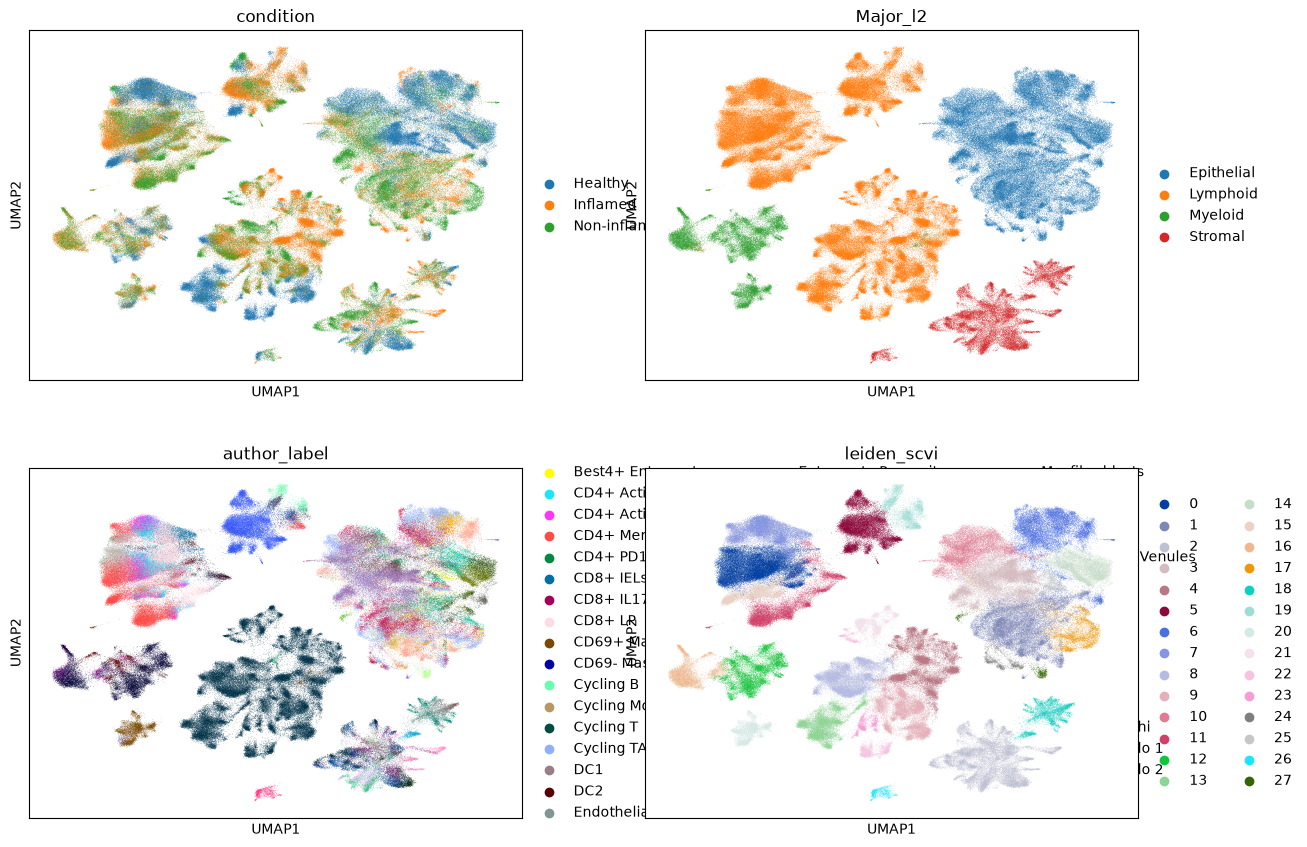

28 scVI clusters


In [10]:
sc.pl.umap(adata, color=["condition", "Major_l2", "author_label", "leiden_scvi"], ncols=2, save="_scvi_overview.png")
print(adata.obs["leiden_scvi"].nunique(), "scVI clusters")



## Do the scVI clusters recover the author's labels?

For each scVI cluster: the dominant author label and its share. High shares (0.8+) mean the integration preserved biology while removing sample effects.

                   top_author_label  share
leiden_scvi                               
24                             TA 2   0.24
1                              TA 2   0.26
2                   WNT2B+ Fos-lo 1   0.26
6                        Cycling TA   0.27
7                           CD8+ LP   0.28
17                       Cycling TA   0.28
19                        Cycling B   0.29
0                       CD4+ Memory   0.32
25                       Cycling TA   0.32
14           Immature Enterocytes 1   0.34
18                      Endothelial   0.40
10                             TA 1   0.42
15                      CD4+ Memory   0.47
11                      CD4+ Memory   0.54
3                              TA 1   0.60
27                             Tuft   0.69
12                      Macrophages   0.76
16                      Macrophages   0.77
5                        Follicular   0.95
4                            Plasma   0.96
20                       CD69+ Mast   0.97
13         

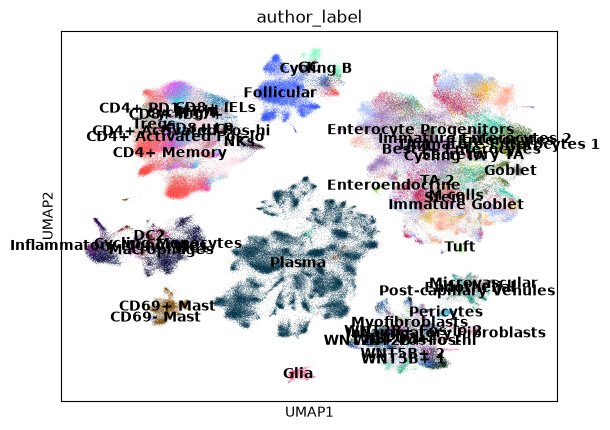

In [11]:
ct = pd.crosstab(adata.obs["leiden_scvi"], adata.obs["author_label"], normalize="index")
summary = pd.DataFrame({"top_author_label": ct.idxmax(axis=1), "share": ct.max(axis=1).round(2)})
print(summary.sort_values("share"))
sc.pl.umap(adata, color="author_label", legend_loc="on data", save="_scvi_author.png")

In [12]:
out = os.path.expanduser("~/Documents/immune-endotypes/data/smillie_uc/adata_scvi.h5ad")
adata.write(out)
print("saved", out)

saved /Users/juehuayu/Documents/immune-endotypes/data/smillie_uc/adata_scvi.h5ad


**Next (notebook 03):** pseudobulk DESeq2 — inflamed vs healthy within each major cell type, and the anti-TNF non-response module (inflammatory fibroblasts, OSM+ monocytes).